In [1]:

# 1. Install gdown
!pip -q install gdown

# 2. Download your Google Drive ZIP file
import gdown
import os

file_id = "1njl-hWUG7OEQVilJ4f8w77YuZe7EXrtM"
zip_path = "/kaggle/working/dataset.zip"

url = f"https://drive.google.com/uc?id={file_id}"

gdown.download(url, zip_path, quiet=False)

# 3. Verify the download
if os.path.exists(zip_path):
    print(f"Download complete: {zip_path}")
    print(f"File size: {os.path.getsize(zip_path) / (1024**3):.2f} GB")
else:
    print("Download failed. Check the Drive sharing permissions.")


Downloading...
From (original): https://drive.google.com/uc?id=1njl-hWUG7OEQVilJ4f8w77YuZe7EXrtM
From (redirected): https://drive.google.com/uc?id=1njl-hWUG7OEQVilJ4f8w77YuZe7EXrtM&confirm=t&uuid=03385ae4-adb8-4f6a-9d12-ad147ec05d87
To: /kaggle/working/dataset.zip
100%|██████████| 804M/804M [00:05<00:00, 156MB/s] 

Download complete: /kaggle/working/dataset.zip
File size: 0.75 GB


In [2]:

import zipfile
import os

zip_path = "/kaggle/working/dataset.zip"
extract_path = "/kaggle/working/dataset"

if os.path.isfile(zip_path) and zipfile.is_zipfile(zip_path):
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_path)
    print("Extracted to:", extract_path)
    print("Files:", os.listdir(extract_path)[:20])
else:
    print("ZIP file is missing, incomplete, or invalid.")


Extracted to: /kaggle/working/dataset
Files: ['noise_project_v2']


In [3]:

import os

folder = "/kaggle/working/dataset/noise_project_v2"

for root, dirs, files in os.walk(folder):
    level = root.replace(folder, "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    subindent = "    " * (level + 1)
    for file in files[:20]:
        print(f"{subindent}{file}")

    if level >= 3:
        dirs.clear()


noise_project_v2/
    noisy_metadata_v2.csv
    b6000_split.csv
    clean_list.csv
    noise_manifest_v2.json
    clean_500/
        S/
            00002604_S_500_slap_03.png
            00002615_S_500_slap_02.png
            00002646_S_500_slap_03.png
            00002615_S_500_slap_03.png
            00002537_S_500_slap_04.png
            00002640_S_500_slap_02.png
            00002456_S_500_slap_01.png
            00002493_S_500_slap_09.png
            00002579_S_500_slap_01.png
            00002581_S_500_slap_06.png
            00002499_S_500_slap_07.png
            00002466_S_500_slap_06.png
            00002646_S_500_slap_08.png
            00002571_S_500_slap_10.png
            00002533_S_500_slap_06.png
            00002650_S_500_slap_06.png
            00002593_S_500_slap_09.png
            00002651_S_500_slap_06.png
            00002560_S_500_slap_03.png
            00002501_S_500_slap_02.png
        R/
            00002381_R_500_slap_04.png
            00002405_R_500_slap_01

In [4]:

from pathlib import Path
from collections import Counter

folder = Path("/kaggle/working/dataset/noise_project_v2")

files = [p for p in folder.rglob("*") if p.is_file()]

print("Total files:", len(files))
print("\nFile types:")
print(Counter(p.suffix.lower() or "[no extension]" for p in files))

print("\nFirst 30 file paths:")
for p in files[:30]:
    print(p.relative_to(folder))


Total files: 4984

File types:
Counter({'.png': 4980, '.csv': 3, '.json': 1})

First 30 file paths:
noisy_metadata_v2.csv
b6000_split.csv
clean_list.csv
noise_manifest_v2.json
noisy_500_v2/S/00002604_S_500_slap_03.png
noisy_500_v2/S/00002615_S_500_slap_02.png
noisy_500_v2/S/00002646_S_500_slap_03.png
noisy_500_v2/S/00002615_S_500_slap_03.png
noisy_500_v2/S/00002537_S_500_slap_04.png
noisy_500_v2/S/00002640_S_500_slap_02.png
noisy_500_v2/S/00002456_S_500_slap_01.png
noisy_500_v2/S/00002493_S_500_slap_09.png
noisy_500_v2/S/00002579_S_500_slap_01.png
noisy_500_v2/S/00002581_S_500_slap_06.png
noisy_500_v2/S/00002499_S_500_slap_07.png
noisy_500_v2/S/00002466_S_500_slap_06.png
noisy_500_v2/S/00002646_S_500_slap_08.png
noisy_500_v2/S/00002571_S_500_slap_10.png
noisy_500_v2/S/00002533_S_500_slap_06.png
noisy_500_v2/S/00002650_S_500_slap_06.png
noisy_500_v2/S/00002593_S_500_slap_09.png
noisy_500_v2/S/00002651_S_500_slap_06.png
noisy_500_v2/S/00002560_S_500_slap_03.png
noisy_500_v2/S/00002501_S_

In [5]:
import os, time, random
from pathlib import Path
import numpy as np, pandas as pd, cv2
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from skimage.morphology import skeletonize
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(DEV)

cuda


In [6]:
IMG_SIZE = 256          # full image resized to IMG_SIZE x IMG_SIZE (must be divisible by 16)
CROP = 192              # training patch size (paper)
BATCH = 16
EPOCHS = 50
LR = 1e-3               # paper
BETAS = (0.5, 0.999)
TARGET_MODE = "gray"    # "gray" = clean image as target, "skeleton" = paper-exact
LAMBDA_REC = 100.0      # weight of weighted-L1 loss
MIN_ALPHA = 4.0         # extra weight near minutiae
SIGMA = 8               # gaussian sigma for minutia weight map (paper)
OF_SIGMA = 8            # smoothing for orientation field
WORKERS = 2

WORK = Path("/kaggle/working")
CACHE = WORK / "cache_v2.npz"
OUT = WORK / "fingergan_out"; OUT.mkdir(exist_ok=True)

In [7]:
# locate dataset folders
NOISY_DIR = next(Path("/kaggle/working/dataset").rglob("noisy_500_v2"))
ROOT = NOISY_DIR.parent
CLEAN_DIR = ROOT / "clean_500"
print("ROOT:", ROOT)

rows = []
for p in sorted(CLEAN_DIR.rglob("*.png")):
    q = NOISY_DIR / p.parent.name / p.name
    if q.exists():
        rows.append(dict(name=p.name, device=p.parent.name,
                         participant=p.name.split("_")[0],
                         clean=str(p), noisy=str(q)))
pairs = pd.DataFrame(rows)
print("pairs:", len(pairs))          # expect 2490

sdf = pd.read_csv(ROOT / "b6000_split.csv")
sdf.columns = [c.lower() for c in sdf.columns]
print(sdf.columns.tolist()); print(sdf.head(3))

# attach split: match either by filename or by participant id
assert "split" in sdf.columns, "no 'split' column, paste sdf.head()"
done = False
for col in sdf.columns:
    if col == "split": continue
    v = sdf[col].astype(str)
    if v.map(os.path.basename).isin(pairs.name).mean() > 0.5:
        m = dict(zip(v.map(os.path.basename), sdf["split"]))
        pairs["split"] = pairs["name"].map(m); done = True; break
    if v.str.zfill(8).isin(pairs.participant).mean() > 0.5:
        m = dict(zip(v.str.zfill(8), sdf["split"]))
        pairs["split"] = pairs["participant"].map(m); done = True; break
assert done, "could not match split csv, paste sdf.head()"

pairs = pairs.dropna(subset=["split"]).reset_index(drop=True)
print(pairs.split.value_counts())    # expect train 1764, val 388, test 338
print(pd.crosstab(pairs.device, pairs.split))

ROOT: /kaggle/working/dataset/noise_project_v2
pairs: 2490
['source', 'key', 'participant', 'device', 'ppi', 'capture', 'frgp', 'finger_name', 'zip_member', 'sha256', 'has_g_minutiae', 'sibling_1000_annotated', 'n_minutiae', 'g_irr_path', 'minutiae_mode', 'group_id', 'g_key', 'items_9_331_minutiae', 'items_9_320', 'items_9_321', 'items_9_325', 'items_9_326', 'has_class_9_307', 'class_9_307', 'has_annotation', 'nfiq2', 'valid', 'nfiq2_bin', 'quality_group', 'split']
  source                     key  participant device  ppi         capture  \
0      b  00002302_R_500_slap_01         2302      R  500  slap-segmented   
1      b  00002302_R_500_slap_02         2302      R  500  slap-segmented   
2      b  00002302_R_500_slap_03         2302      R  500  slap-segmented   

   frgp finger_name                                         zip_member  \
0     1     R thumb  sd302b/images/baseline/R/500/slap-segmented/pn...   
1     2     R index  sd302b/images/baseline/R/500/slap-segmented/pn...   

In [8]:
def load_gray(path):
    im = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    return cv2.resize(im, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)

def make_skeleton(c):
    sm = cv2.GaussianBlur(c, (3, 3), 0)
    bw = cv2.adaptiveThreshold(sm, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                               cv2.THRESH_BINARY_INV, 15, 3)   # ridges dark -> white
    bw = cv2.medianBlur(bw, 3)
    return skeletonize(bw > 0)

def minutiae_map(skel):
    s = skel.astype(np.uint8)
    p = np.pad(s, 1).astype(np.int16)
    nb = [p[0:-2,0:-2], p[0:-2,1:-1], p[0:-2,2:], p[1:-1,2:],
          p[2:,2:],     p[2:,1:-1],   p[2:,0:-2], p[1:-1,0:-2]]
    cn = sum(np.abs(nb[i] - nb[(i + 1) % 8]) for i in range(8)) // 2   # crossing number
    m = (s == 1) & ((cn == 1) | (cn == 3))      # ending / bifurcation
    m[:12, :] = False; m[-12:, :] = False; m[:, :12] = False; m[:, -12:] = False
    return m

def orientation_field(c):
    f = cv2.GaussianBlur(c.astype(np.float32) / 255, (0, 0), 1.0)
    gx = cv2.Sobel(f, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(f, cv2.CV_32F, 0, 1, ksize=3)
    gxx = cv2.GaussianBlur(gx * gx, (0, 0), OF_SIGMA)
    gyy = cv2.GaussianBlur(gy * gy, (0, 0), OF_SIGMA)
    gxy = cv2.GaussianBlur(gx * gy, (0, 0), OF_SIGMA)
    theta = 0.5 * np.arctan2(2 * gxy, gxx - gyy)
    return ((theta + np.pi / 2) % np.pi) / np.pi          # [0,1)

def build_arrays(df):
    N, S = len(df), IMG_SIZE
    A = {k: np.zeros((N, S, S), np.uint8) for k in ["noisy", "clean", "skel", "of", "w"]}
    for i, r in enumerate(tqdm(df.itertuples(), total=N)):
        c, n = load_gray(r.clean), load_gray(r.noisy)
        sk = make_skeleton(c)
        mm = minutiae_map(sk)
        w = np.clip(cv2.GaussianBlur(mm.astype(np.float32), (0, 0), SIGMA) * (2 * np.pi * SIGMA**2), 0, 1)
        A["clean"][i], A["noisy"][i] = c, n
        A["skel"][i] = cv2.dilate(sk.astype(np.uint8) * 255, np.ones((3, 3), np.uint8))
        A["of"][i] = (orientation_field(c) * 255).astype(np.uint8)
        A["w"][i] = (w * 255).astype(np.uint8)
    return A

if CACHE.exists():
    A = dict(np.load(CACHE)); print("loaded cache")
else:
    A = build_arrays(pairs); np.savez(CACHE, **A); print("cache saved")
pairs.to_csv(OUT / "pairs_with_split.csv", index=False)

  0%|          | 0/2490 [00:00<?, ?it/s]

cache saved


{'train': 1764, 'val': 388, 'test': 338}


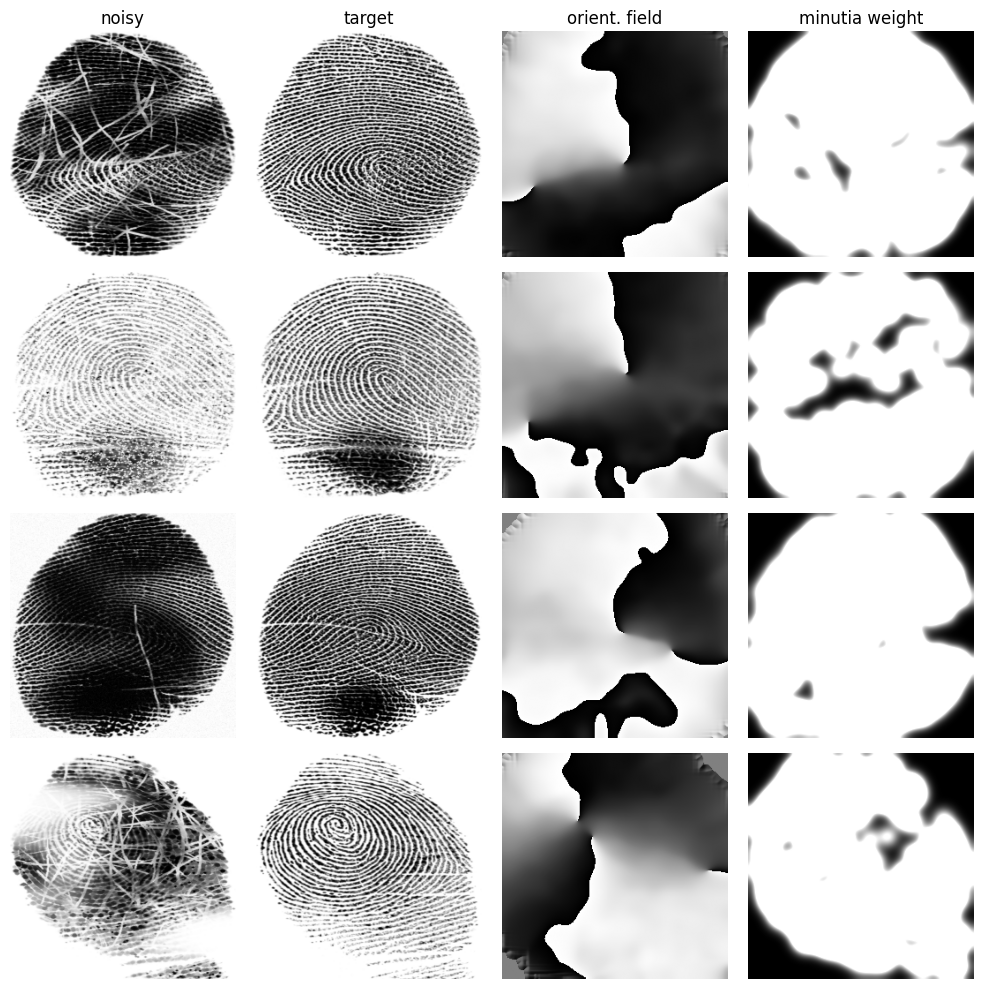

In [9]:
class FPDataset(Dataset):
    def __init__(self, A, idx, train):
        self.A, self.idx, self.train = A, np.array(idx), train
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]; A = self.A
        tgt = A["skel"][j] if TARGET_MODE == "skeleton" else A["clean"][j]
        arrs = [A["noisy"][j], tgt, A["of"][j], A["w"][j]]
        if self.train:
            t = np.random.randint(0, IMG_SIZE - CROP + 1)
            l = np.random.randint(0, IMG_SIZE - CROP + 1)
            arrs = [a[t:t + CROP, l:l + CROP] for a in arrs]
        x = torch.from_numpy(np.stack(arrs)).float() / 255
        noisy, tgt, of, w = x[0:1], x[1:2], x[2:3], 1 + MIN_ALPHA * x[3:4]
        return noisy, tgt, of, w

idx = {s: pairs.index[pairs.split == s].values for s in ["train", "val", "test"]}
train_dl = DataLoader(FPDataset(A, idx["train"], True),  BATCH, shuffle=True, num_workers=WORKERS, drop_last=True, pin_memory=True)
val_dl   = DataLoader(FPDataset(A, idx["val"],   False), BATCH, shuffle=False, num_workers=WORKERS)
print({k: len(v) for k, v in idx.items()})

# sanity visual
noisy, tgt, of, w = next(iter(DataLoader(FPDataset(A, idx["train"][:4], False), 4)))
fig, ax = plt.subplots(4, 4, figsize=(10, 10))
for r in range(4):
    for c, (im, t) in enumerate(zip([noisy, tgt, of, w], ["noisy", "target", "orient. field", "minutia weight"])):
        ax[r, c].imshow(im[r, 0], cmap="gray"); ax[r, c].axis("off")
        if r == 0: ax[r, c].set_title(t)
plt.tight_layout(); plt.show()

In [10]:
def cbl(i, o, k, s, p):
    return nn.Sequential(nn.Conv2d(i, o, k, s, p, bias=False), nn.BatchNorm2d(o), nn.LeakyReLU(0.2, True))
def up(i, o):
    return nn.Sequential(nn.ConvTranspose2d(i, o, 2, 2, bias=False), nn.BatchNorm2d(o), nn.LeakyReLU(0.2, True))

class UNetG(nn.Module):
    def __init__(self):
        super().__init__()
        self.c1 = nn.Sequential(cbl(1, 64, 3, 1, 1), cbl(64, 64, 3, 1, 1))
        self.c2 = nn.Sequential(cbl(64, 128, 2, 2, 0), cbl(128, 128, 3, 1, 1))
        self.c3 = nn.Sequential(cbl(128, 256, 2, 2, 0), cbl(256, 256, 3, 1, 1))
        self.c4 = nn.Sequential(cbl(256, 512, 2, 2, 0), cbl(512, 512, 3, 1, 1))
        self.c5 = cbl(512, 1024, 2, 2, 0)
        self.u1, self.d1 = up(1024, 512), cbl(1024, 512, 3, 1, 1)
        self.u2, self.d2 = up(512, 256),  cbl(512, 256, 3, 1, 1)
        self.u3, self.d3 = up(256, 128),  cbl(256, 128, 3, 1, 1)
        self.u4, self.d4 = up(128, 64),   cbl(128, 64, 3, 1, 1)
        self.out = nn.Sequential(nn.Conv2d(64, 1, 3, 1, 1), nn.Sigmoid())
    def forward(self, x):
        e1 = self.c1(x); e2 = self.c2(e1); e3 = self.c3(e2); e4 = self.c4(e3); e5 = self.c5(e4)
        d = self.d1(torch.cat([self.u1(e5), e4], 1))
        d = self.d2(torch.cat([self.u2(d), e3], 1))
        d = self.d3(torch.cat([self.u3(d), e2], 1))
        d = self.d4(torch.cat([self.u4(d), e1], 1))
        return self.out(d)

class PatchD(nn.Module):   # input: 2 channels (image + orientation field)
    def __init__(self):
        super().__init__()
        ch = [2, 64, 64, 128, 128, 256, 256]
        self.net = nn.Sequential(*[cbl(ch[i], ch[i + 1], 4, 2, 1) for i in range(6)],
                                 nn.Conv2d(256, 1, 3, 1, 1))     # logits, sigmoid inside BCEWithLogits
    def forward(self, x): return self.net(x)

G, D = UNetG().to(DEV), PatchD().to(DEV)
print(f"G params: {sum(p.numel() for p in G.parameters())/1e6:.1f}M | D params: {sum(p.numel() for p in D.parameters())/1e6:.2f}M")
x = torch.rand(2, 1, CROP, CROP, device=DEV)
print(G(x).shape, D(torch.rand(2, 2, CROP, CROP, device=DEV)).shape)

G params: 15.0M | D params: 2.04M
torch.Size([2, 1, 192, 192]) torch.Size([2, 1, 3, 3])


In [11]:
optG = torch.optim.Adam(G.parameters(), lr=LR, betas=BETAS)
optD = torch.optim.Adam(D.parameters(), lr=LR, betas=BETAS)
bce = nn.BCEWithLogitsLoss()

def psnr_t(a, b):
    mse = ((a - b) ** 2).mean((1, 2, 3)).clamp_min(1e-10)
    return (10 * torch.log10(1 / mse)).sum().item()

@torch.no_grad()
def validate():
    G.eval(); l1 = ps = base = n = 0
    for noisy, tgt, of, w in val_dl:
        noisy, tgt = noisy.to(DEV), tgt.to(DEV)
        out = G(noisy)
        l1 += (out - tgt).abs().mean((1, 2, 3)).sum().item()
        ps += psnr_t(out, tgt); base += psnr_t(noisy, tgt); n += len(noisy)
    return l1 / n, ps / n, base / n

@torch.no_grad()
def save_samples(ep, k=4):
    G.eval()
    noisy, tgt, _, _ = next(iter(DataLoader(FPDataset(A, idx["val"][:k], False), k)))
    out = G(noisy.to(DEV)).cpu()
    fig, ax = plt.subplots(k, 3, figsize=(7, 2.4 * k))
    for r in range(k):
        for c, (im, t) in enumerate(zip([noisy, out, tgt], ["noisy", "enhanced", "target"])):
            ax[r, c].imshow(im[r, 0], cmap="gray", vmin=0, vmax=1); ax[r, c].axis("off")
            if r == 0: ax[r, c].set_title(t)
    plt.tight_layout(); plt.savefig(OUT / f"samples_ep{ep:03d}.png", dpi=100); plt.close()

hist = []
for ep in range(1, EPOCHS + 1):
    G.train(); D.train(); t0 = time.time()
    s = dict(d=0., adv=0., rec=0.); nb = 0
    for noisy, tgt, of, w in tqdm(train_dl, leave=False, desc=f"ep{ep}"):
        noisy, tgt, of, w = noisy.to(DEV), tgt.to(DEV), of.to(DEV), w.to(DEV)
        fake = G(noisy)

        # --- discriminator ---
        d_real = D(torch.cat([tgt, of], 1))
        d_fake = D(torch.cat([fake.detach(), of], 1))
        lossD = 0.5 * (bce(d_real, torch.ones_like(d_real)) + bce(d_fake, torch.zeros_like(d_fake)))
        optD.zero_grad(set_to_none=True); lossD.backward(); optD.step()

        # --- generator ---
        g_out = D(torch.cat([fake, of], 1))
        adv = bce(g_out, torch.ones_like(g_out))
        rec = (w * (tgt - fake).abs()).mean()
        lossG = adv + LAMBDA_REC * rec
        optG.zero_grad(set_to_none=True); lossG.backward(); optG.step()

        s["d"] += lossD.item(); s["adv"] += adv.item(); s["rec"] += rec.item(); nb += 1

    v_l1, v_psnr, v_base = validate()
    row = dict(epoch=ep, d_loss=s["d"] / nb, g_adv=s["adv"] / nb, g_rec=s["rec"] / nb,
               val_l1=v_l1, val_psnr=v_psnr, noisy_psnr=v_base, sec=time.time() - t0)
    hist.append(row); pd.DataFrame(hist).to_csv(OUT / "history.csv", index=False)
    print(f"ep {ep:02d} | D {row['d_loss']:.3f} | Gadv {row['g_adv']:.3f} | Grec {row['g_rec']:.4f} | "
          f"val L1 {v_l1:.4f} | val PSNR {v_psnr:.2f} (noisy {v_base:.2f}) | {row['sec']:.0f}s")
    if ep % 5 == 0 or ep == 1: save_samples(ep)

torch.save({"G": G.state_dict(), "D": D.state_dict()}, OUT / "fingergan_final.pt")

ep1:   0%|          | 0/110 [00:00<?, ?it/s]

ep 01 | D 0.675 | Gadv 0.830 | Grec 0.5887 | val L1 0.0954 | val PSNR 15.99 (noisy 14.19) | 90s


ep2:   0%|          | 0/110 [00:00<?, ?it/s]

ep 02 | D 0.603 | Gadv 1.081 | Grec 0.5290 | val L1 0.0836 | val PSNR 16.82 (noisy 14.19) | 57s


ep3:   0%|          | 0/110 [00:00<?, ?it/s]

ep 03 | D 0.532 | Gadv 1.338 | Grec 0.5168 | val L1 0.1117 | val PSNR 14.62 (noisy 14.19) | 67s


... (99 outputs left out)

ep49:   0%|          | 0/110 [00:00<?, ?it/s]

ep 49 | D 0.575 | Gadv 1.153 | Grec 0.3477 | val L1 0.0605 | val PSNR 18.91 (noisy 14.19) | 56s


ep50:   0%|          | 0/110 [00:00<?, ?it/s]

ep 50 | D 0.589 | Gadv 1.153 | Grec 0.3460 | val L1 0.0588 | val PSNR 19.26 (noisy 14.19) | 66s


best val PSNR 19.56 at epoch 43 | last epoch 50 val PSNR 19.26
noisy baseline PSNR 14.19


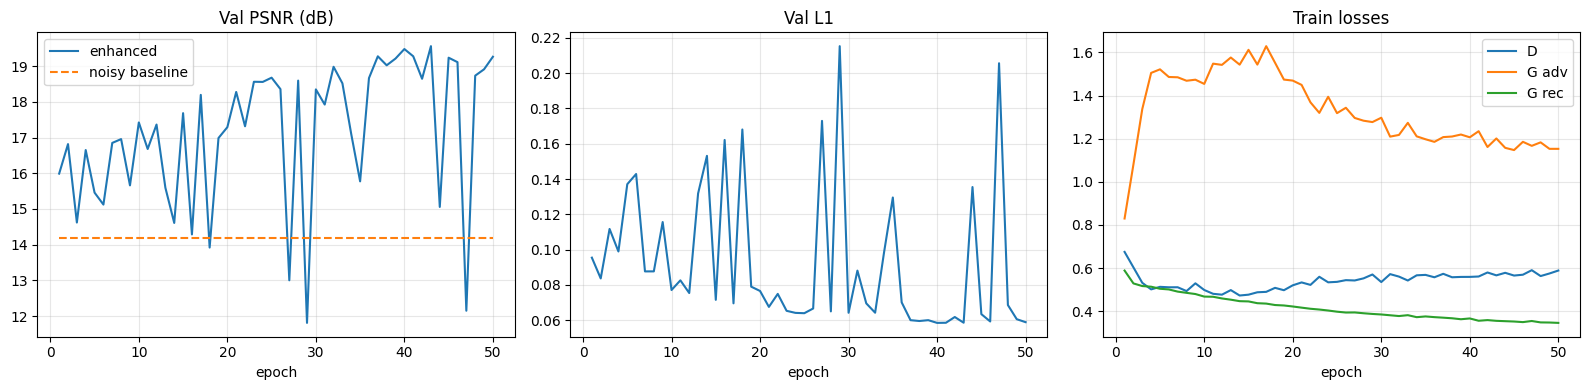

In [12]:
h = pd.read_csv(OUT / "history.csv")
best = h.loc[h.val_psnr.idxmax()]
print(f"best val PSNR {best.val_psnr:.2f} at epoch {int(best.epoch)} | last epoch {int(h.epoch.iloc[-1])} val PSNR {h.val_psnr.iloc[-1]:.2f}")
print(f"noisy baseline PSNR {h.noisy_psnr.iloc[-1]:.2f}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(h.epoch, h.val_psnr, label="enhanced"); ax[0].plot(h.epoch, h.noisy_psnr, "--", label="noisy baseline")
ax[0].set_title("Val PSNR (dB)"); ax[0].legend()
ax[1].plot(h.epoch, h.val_l1); ax[1].set_title("Val L1")
ax[2].plot(h.epoch, h.d_loss, label="D"); ax[2].plot(h.epoch, h.g_adv, label="G adv"); ax[2].plot(h.epoch, h.g_rec, label="G rec")
ax[2].set_title("Train losses"); ax[2].legend()
for a in ax: a.set_xlabel("epoch"); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT / "training_curves.png", dpi=120); plt.show()

In [13]:
from skimage.metrics import structural_similarity as ssim_fn

# optional: reload weights instead of using the in-memory model
# ck = torch.load(OUT / "fingergan_final.pt", map_location=DEV); G.load_state_dict(ck["G"])

test_idx = idx["test"]
test_dl = DataLoader(FPDataset(A, test_idx, False), BATCH, shuffle=False, num_workers=WORKERS)
G.eval(); outs = []
with torch.no_grad():
    for noisy, *_ in test_dl:
        outs.append(G(noisy.to(DEV)).cpu().numpy()[:, 0])
enh = np.concatenate(outs)                                  # (N,256,256) in [0,1]
noisy_t = A["noisy"][test_idx].astype(np.float32) / 255
clean_t = A["clean"][test_idx].astype(np.float32) / 255

def metrics(x, ref):
    mse = np.mean((x - ref) ** 2)
    return dict(psnr=10 * np.log10(1 / max(mse, 1e-10)),
                ssim=ssim_fn(ref, x, data_range=1.0),
                rmse=np.sqrt(mse) * 255)

rows = []
for k, j in enumerate(tqdm(test_idx)):
    r = pairs.loc[j]
    e, n = metrics(enh[k], clean_t[k]), metrics(noisy_t[k], clean_t[k])
    rows.append(dict(name=r["name"], device=r["device"], participant=r["participant"],
                     **{f"noisy_{m}": v for m, v in n.items()},
                     **{f"enh_{m}": v for m, v in e.items()}))
res = pd.DataFrame(rows)
for m in ["psnr", "ssim", "rmse"]:
    res[f"gain_{m}"] = res[f"enh_{m}"] - res[f"noisy_{m}"]
res.to_csv(OUT / "test_metrics_per_image.csv", index=False)

summ = res[[c for c in res.columns if c.startswith(("noisy_", "enh_"))]].agg(["mean", "std"]).T
print(summ.round(4))
print("\nPer device (mean):")
print(res.groupby("device")[[c for c in res.columns if c.startswith(("noisy_", "enh_"))]].mean().round(4))

  0%|          | 0/338 [00:00<?, ?it/s]

               mean      std
noisy_psnr  14.2667   2.9594
noisy_ssim   0.7289   0.1359
noisy_rmse  52.2094  17.4776
enh_psnr    19.2483   2.8090
enh_ssim     0.8912   0.0662
enh_rmse    29.3093   9.8025

Per device (mean):
        noisy_psnr  noisy_ssim  noisy_rmse   enh_psnr  enh_ssim   enh_rmse
device                                                                    
R        11.651300      0.5882   68.081398  16.698999    0.8342  38.503799
S        12.419100      0.6204   63.006500  17.756201    0.8550  34.136501
U        16.077499      0.8317   41.471901  20.852501    0.9271  23.783100
V        16.000601      0.8256   41.842098  20.790199    0.9290  24.051500


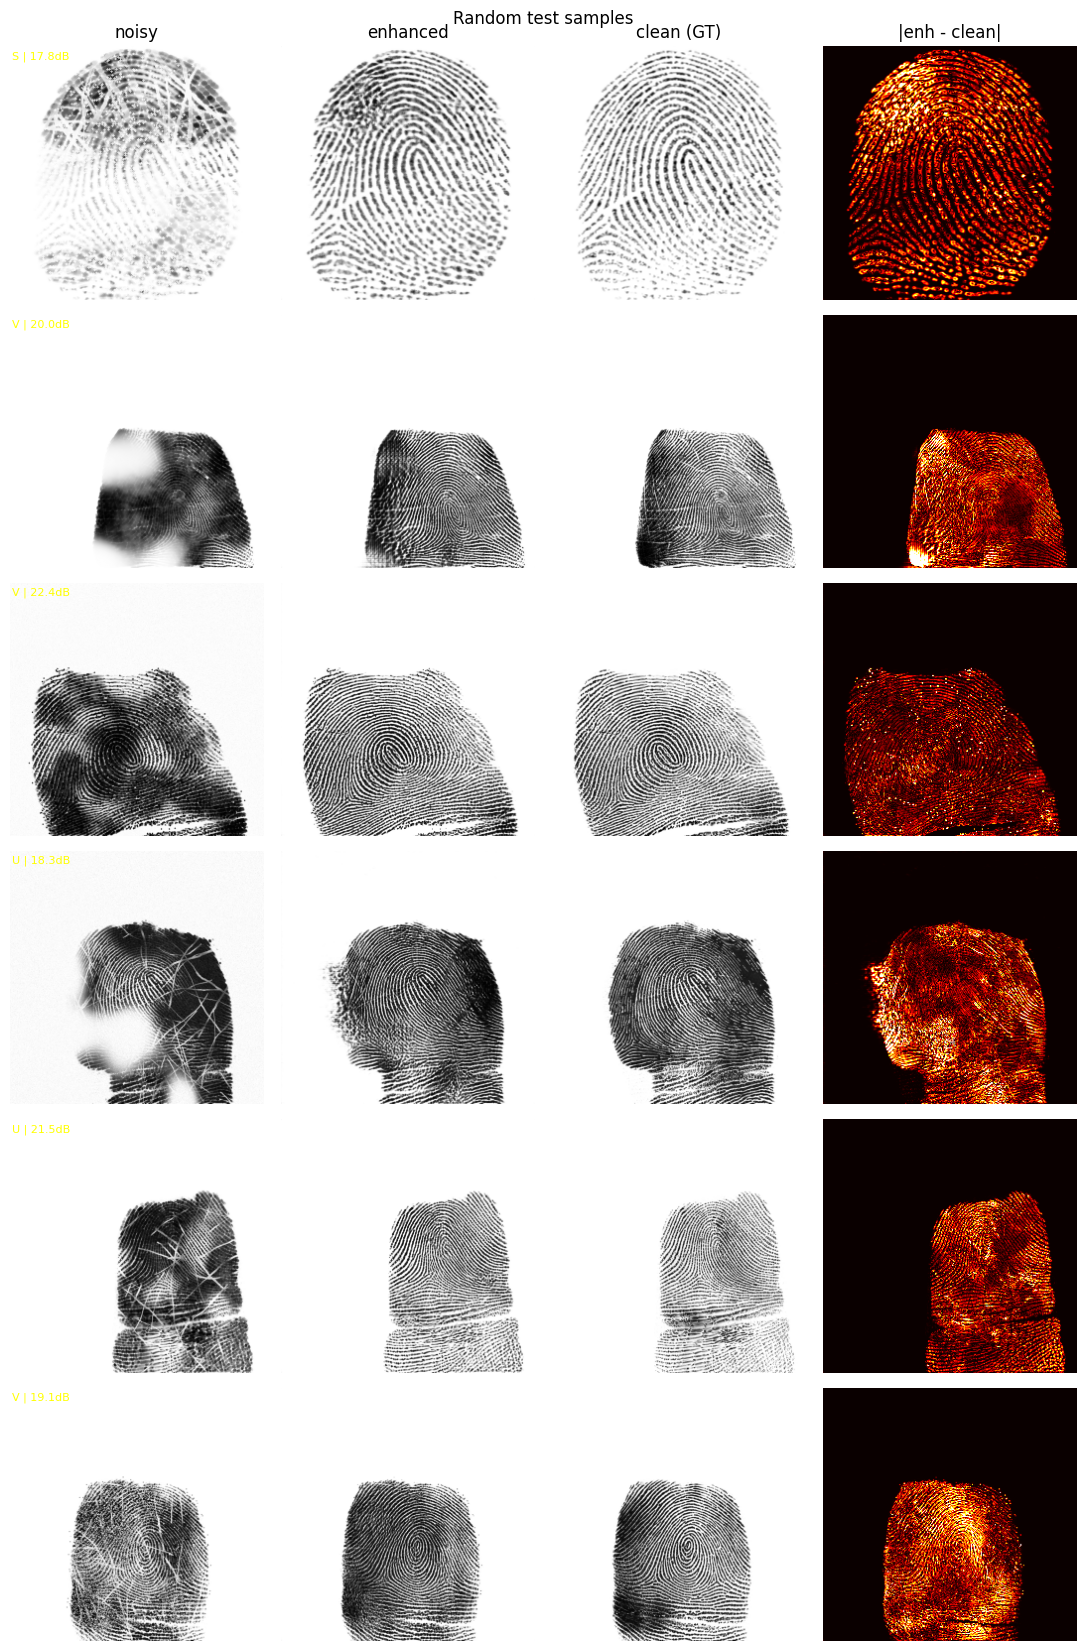

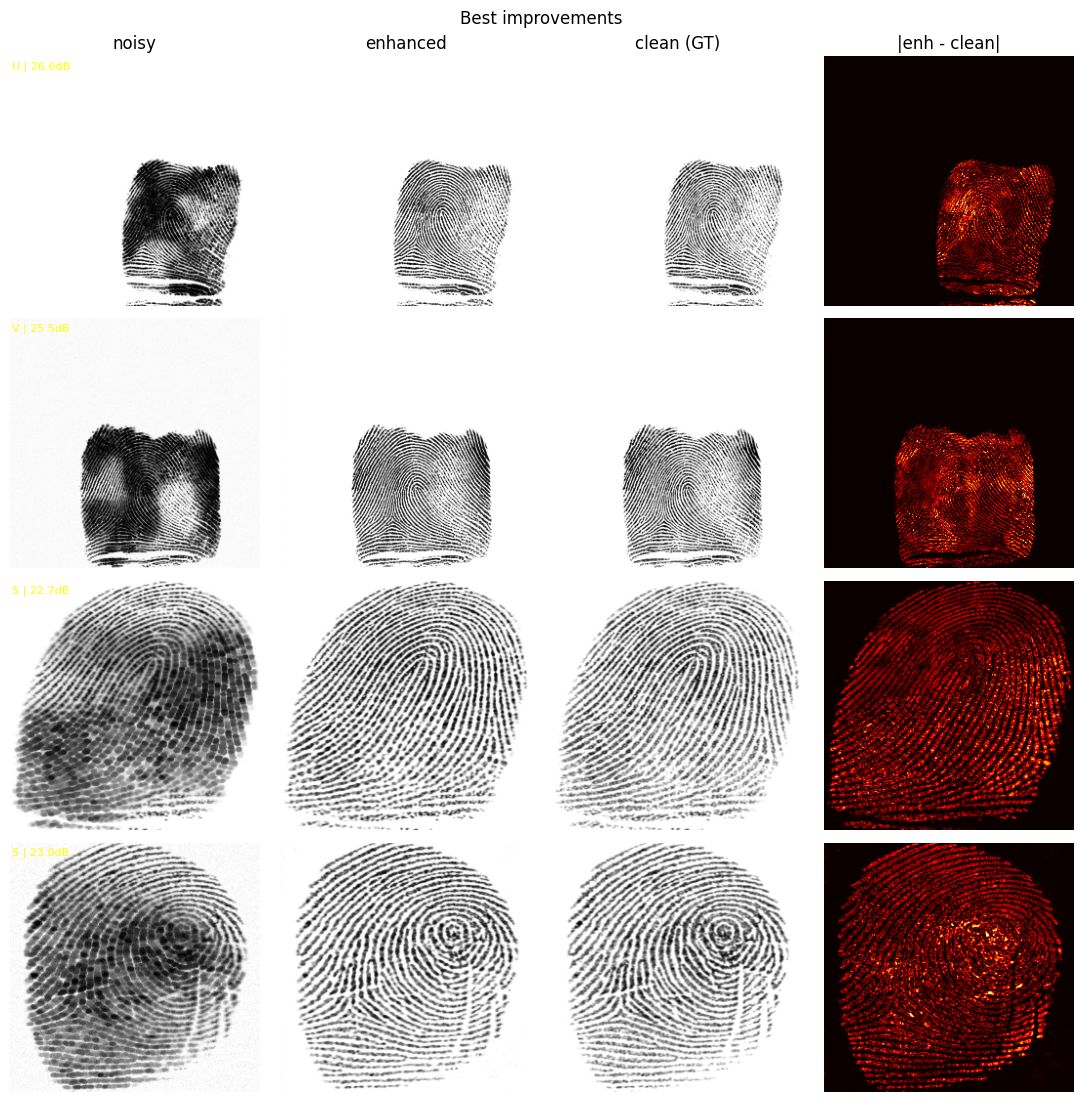

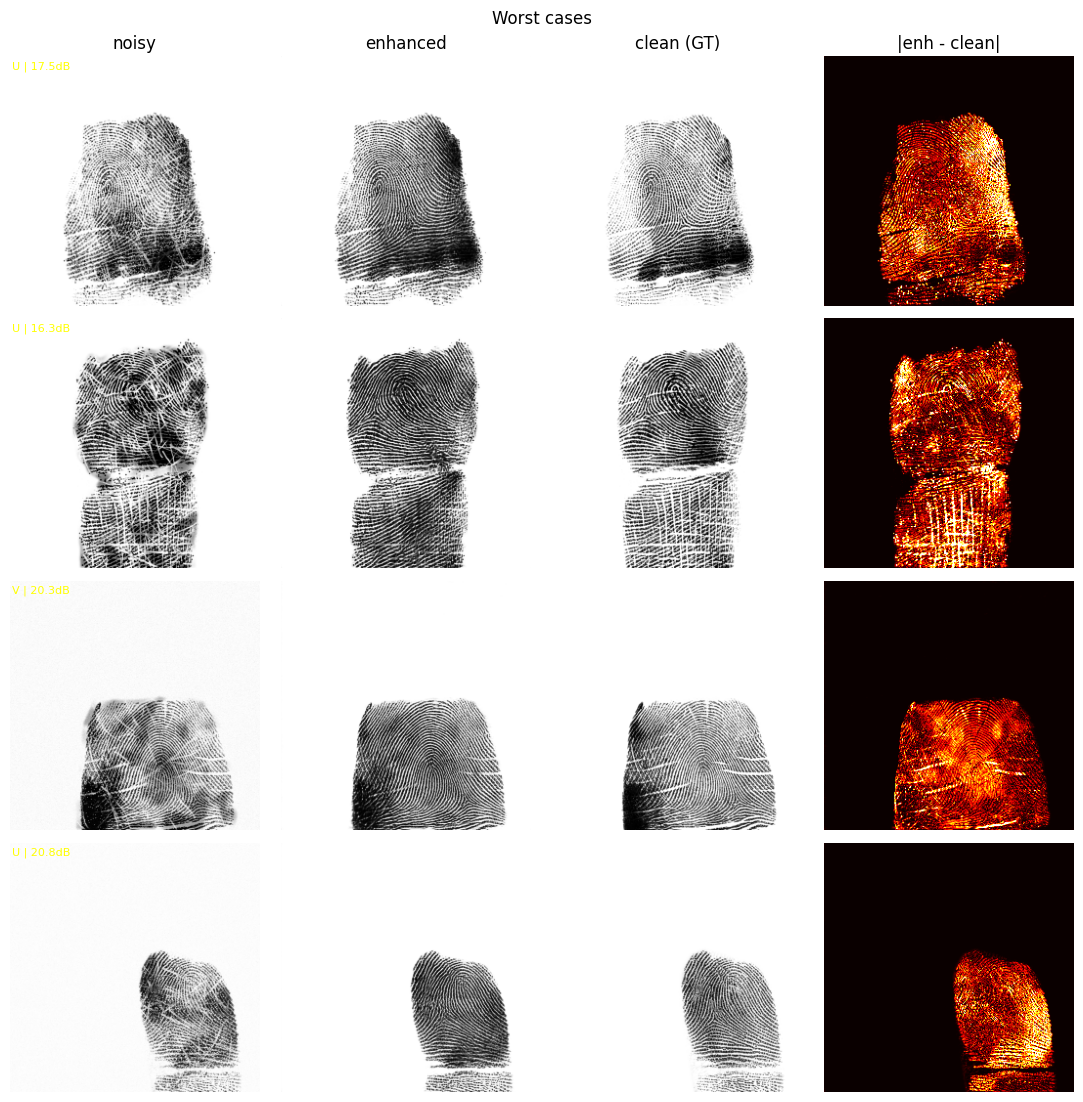

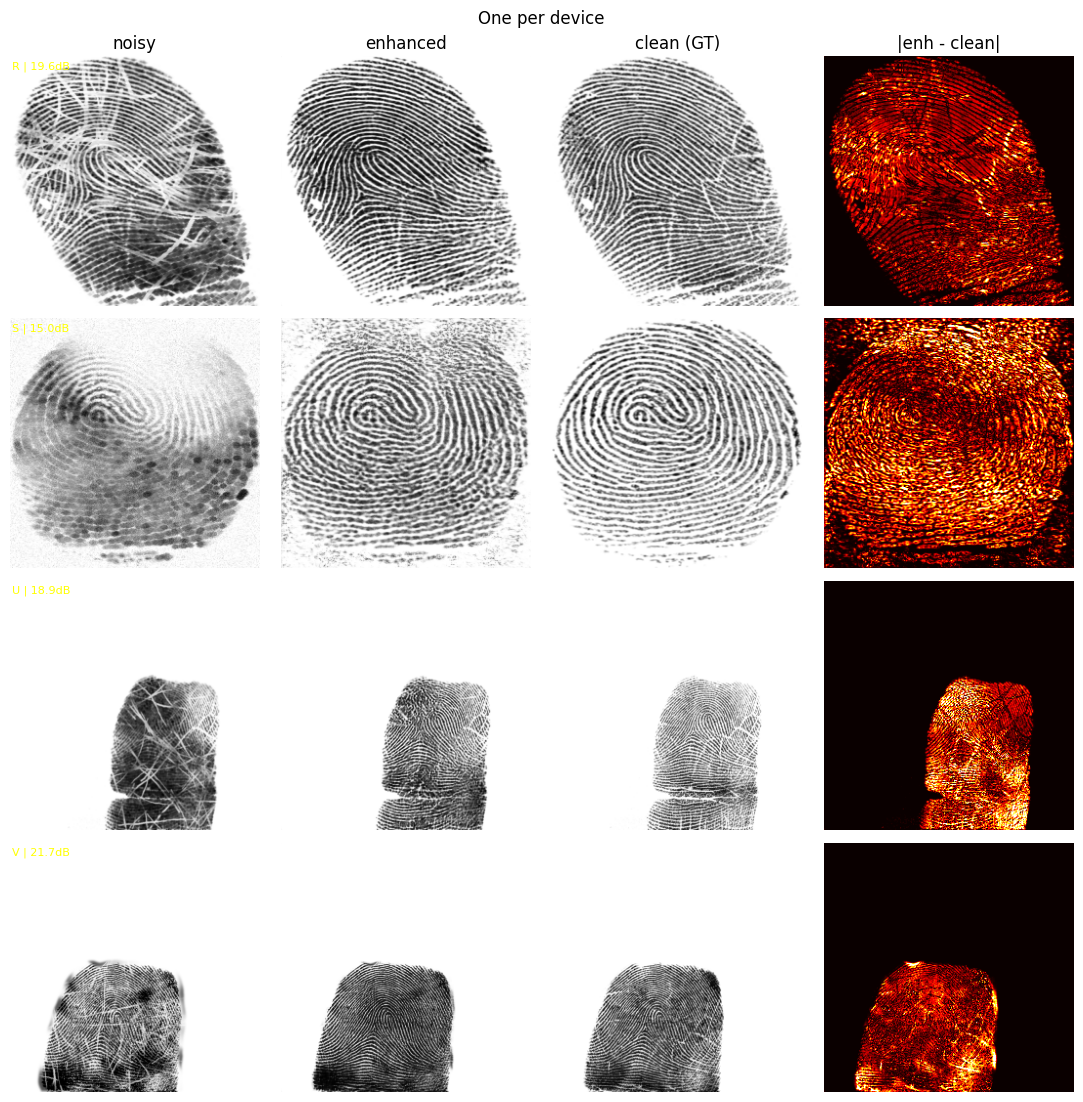

In [14]:
def show(sel, title, fname):
    k = len(sel)
    fig, ax = plt.subplots(k, 4, figsize=(11, 2.8 * k))
    ax = np.atleast_2d(ax)
    for r, i in enumerate(sel):
        diff = np.abs(enh[i] - clean_t[i])
        for c, (im, t) in enumerate(zip([noisy_t[i], enh[i], clean_t[i], diff],
                                        ["noisy", "enhanced", "clean (GT)", "|enh - clean|"])):
            ax[r, c].imshow(im, cmap="gray" if c < 3 else "hot", vmin=0, vmax=1 if c < 3 else 0.5)
            ax[r, c].axis("off")
            if r == 0: ax[r, c].set_title(t)
        ax[r, 0].text(2, 12, f"{res.device[i]} | {res.enh_psnr[i]:.1f}dB", color="yellow", fontsize=8)
    plt.suptitle(title); plt.tight_layout(); plt.savefig(OUT / fname, dpi=110); plt.show()

order = res.gain_psnr.sort_values().index.values
rng = np.random.RandomState(0)
show(rng.choice(len(res), 6, replace=False), "Random test samples", "vis_random.png")
show(order[-4:][::-1], "Best improvements", "vis_best.png")
show(order[:4], "Worst cases", "vis_worst.png")

# one sample per device
show([res.index[res.device == d][0] for d in sorted(res.device.unique())], "One per device", "vis_devices.png")

/tmp/ipykernel_49/253939156.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[1, 1].boxplot([res.enh_psnr[res.device == d] for d in devs], labels=devs); ax[1, 1].set_title("Enhanced PSNR by device")
/tmp/ipykernel_49/253939156.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[1, 2].boxplot([res.gain_ssim[res.device == d] for d in devs], labels=devs); ax[1, 2].set_title("SSIM gain by device")


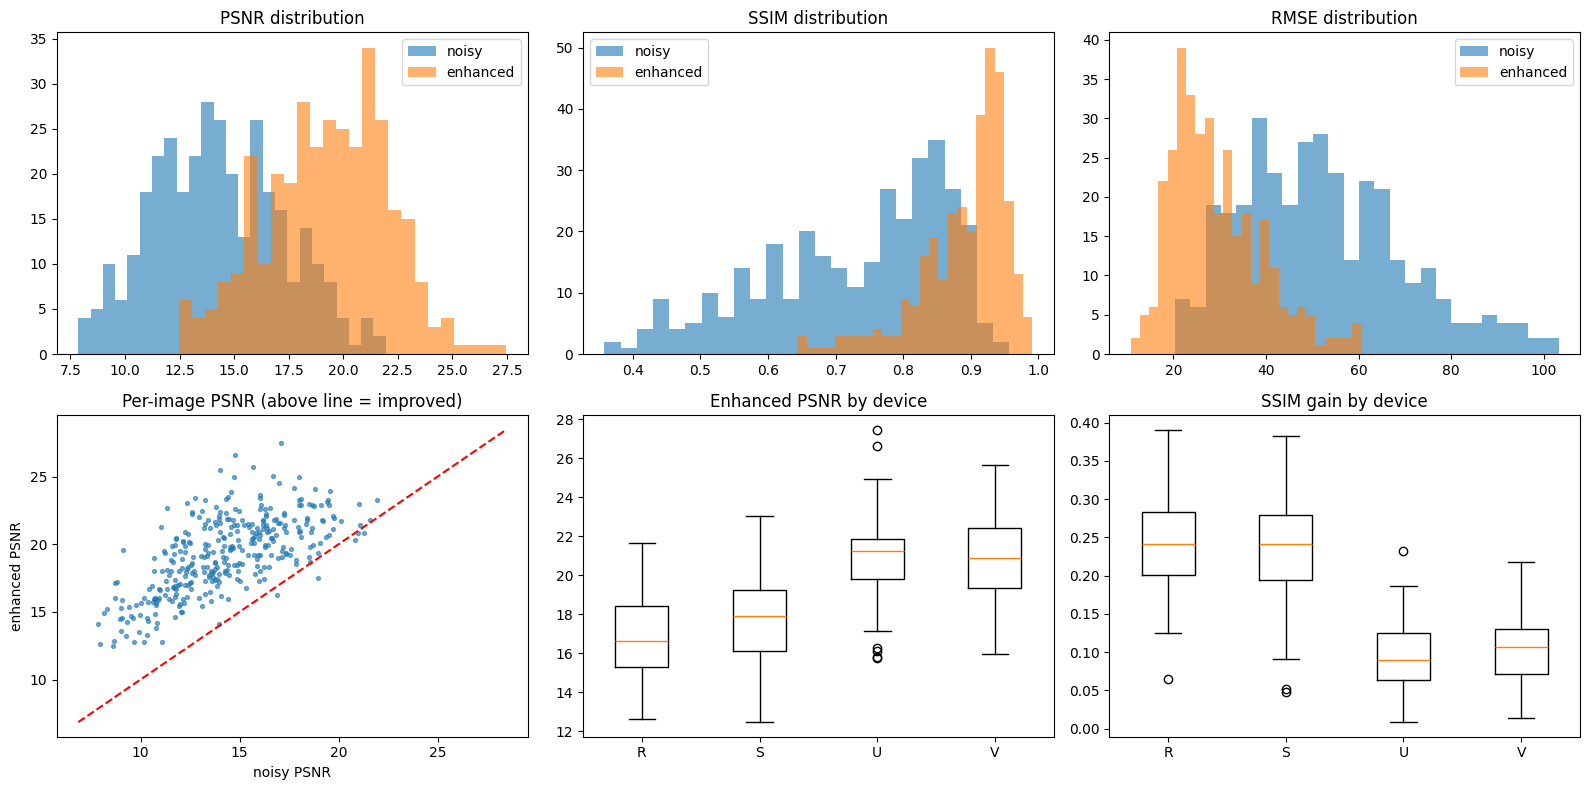

images improved (PSNR): 98.5207100591716 %


In [15]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for a, m in zip(ax[0], ["psnr", "ssim", "rmse"]):
    a.hist(res[f"noisy_{m}"], bins=25, alpha=.6, label="noisy")
    a.hist(res[f"enh_{m}"], bins=25, alpha=.6, label="enhanced")
    a.set_title(m.upper() + " distribution"); a.legend()
ax[1, 0].scatter(res.noisy_psnr, res.enh_psnr, s=8, alpha=.6)
lim = [res.noisy_psnr.min() - 1, res.enh_psnr.max() + 1]; ax[1, 0].plot(lim, lim, "r--")
ax[1, 0].set_xlabel("noisy PSNR"); ax[1, 0].set_ylabel("enhanced PSNR"); ax[1, 0].set_title("Per-image PSNR (above line = improved)")
devs = sorted(res.device.unique())
ax[1, 1].boxplot([res.enh_psnr[res.device == d] for d in devs], labels=devs); ax[1, 1].set_title("Enhanced PSNR by device")
ax[1, 2].boxplot([res.gain_ssim[res.device == d] for d in devs], labels=devs); ax[1, 2].set_title("SSIM gain by device")
plt.tight_layout(); plt.savefig(OUT / "metric_graphs.png", dpi=120); plt.show()
print("images improved (PSNR):", (res.gain_psnr > 0).mean() * 100, "%")

In [18]:
!apt-get update -qq
!apt-get install -y -qq build-essential cmake git libssl-dev libopenjp2-7-dev libpng-dev libtiff-dev libwebp-dev libsqlite3-dev libdb-dev libdb++-dev libhwloc-dev libjpeg-dev zlib1g-dev > /dev/null

W: https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64/InRelease: Key is stored in legacy trusted.gpg keyring (/etc/apt/trusted.gpg), see the DEPRECATION section in apt-key(8) for details.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [19]:
!rm -rf /kaggle/working/NFIQ2_src/build
!cd /kaggle/working/NFIQ2_src && cmake -S . -B build -DCMAKE_BUILD_TYPE=Release 2>&1 | tail -5
!cd /kaggle/working/NFIQ2_src && cmake --build build -j4 2>&1 | tail -15

-- NFIQ 2 Superbuild
-- NFIQ2 git hash 69c39d9
-- Configuring done (0.6s)
-- Generating done (0.0s)
-- Build files have been written to: /kaggle/working/NFIQ2_src/build

-- Build files have been written to: /kaggle/working/NFIQ2_src/build/nfiq2api-prefix/src/nfiq2api-build
[ 96%] Performing build step for 'nfiq2api'
[ 33%] Building CXX object CMakeFiles/Nfiq2Api.dir/nfiq2api.cpp.o
[ 66%] Building CXX object CMakeFiles/Nfiq2Api.dir/version.GNU.Linux.cpp.o
[100%] Linking CXX static library libNfiq2Api.a
[100%] Built target Nfiq2Api
[ 98%] Performing install step for 'nfiq2api'
[100%] Built target Nfiq2Api
Install the project...
-- Install configuration: "Release"
-- Installing: /kaggle/working/NFIQ2_src/build/install_staging/nfiq2/lib/libNfiq2Api.a
-- Installing: /kaggle/working/NFIQ2_src/build/install_staging/nfiq2/include/nfiq2api.h
[100%] Completed 'nfiq2api'
[100%] Built target nfiq2api


In [21]:
import os, glob, subprocess
root = "/kaggle/working/NFIQ2_src/build"
cands = [p for p in glob.glob(f"{root}/**/*", recursive=True)
         if os.path.isfile(p) and os.access(p, os.X_OK)
         and os.path.basename(p).lower() == "nfiq2"]
print(cands)
print(os.listdir(f"{root}/install_staging/nfiq2"))
print(glob.glob(f"{root}/install_staging/nfiq2/bin/*"))

exe = cands[0]
print(subprocess.run([exe, "--help"], capture_output=True, text=True))

['/kaggle/working/NFIQ2_src/build/nfiq2-prefix/src/nfiq2-build/nfiq2', '/kaggle/working/NFIQ2_src/build/install_staging/nfiq2/bin/nfiq2']
['include', 'lib', 'bin', 'share']
['/kaggle/working/NFIQ2_src/build/install_staging/nfiq2/bin/nfiq2', '/kaggle/working/NFIQ2_src/build/install_staging/nfiq2/bin/setup_vars_opencv4.sh']
CompletedProcess(args=['/kaggle/working/NFIQ2_src/build/nfiq2-prefix/src/nfiq2-build/nfiq2', '--help'], returncode=1, stdout='\n                               Welcome to NFIQ2\n\n      Please provide individual files or directories to the command line.\n            If you would like to use one of the flags listed below,\n              please include them before any standard arguments.\n\nCurrently implemented flags and their functions: \n-i [file/directory path]: Processing provided Images and Directories\n-f [batch file path]: Processing provided batch files\n-o [file path]: Saving all output to a specified file\n-j [# of threads]: Enables Multi-Threading for Batch a

In [22]:
exe = "/kaggle/working/NFIQ2_src/build/install_staging/nfiq2/bin/nfiq2"
print(os.path.isfile(exe), os.access(exe, os.X_OK))

True True


In [24]:
import shutil
nf_dir = OUT / "nfiq2"; shutil.rmtree(nf_dir, ignore_errors=True)
for s in ["noisy", "enhanced", "clean"]:
    (nf_dir / s).mkdir(parents=True)

for k, j in enumerate(tqdm(test_idx)):
    r = pairs.loc[j]
    cl = cv2.imread(r["clean"], cv2.IMREAD_GRAYSCALE); H, W = cl.shape
    no = cv2.imread(r["noisy"], cv2.IMREAD_GRAYSCALE)
    en = cv2.resize((enh[k] * 255).clip(0, 255).astype(np.uint8), (W, H), interpolation=cv2.INTER_CUBIC)
    for s, im in [("noisy", no), ("enhanced", en), ("clean", cl)]:
        cv2.imwrite(str(nf_dir / s / f"{k:04d}.png"), im)

print("original size example:", H, W)
print({s: len(list((nf_dir / s).glob("*.png"))) for s in ["noisy", "enhanced", "clean"]})   # expect 338 each

def run_nfiq2(folder):
    out_csv = folder.parent / f"{folder.name}_scores.csv"
    if out_csv.exists():
        out_csv.unlink()
    p = subprocess.run([exe, "-F", "-i", str(folder), "-o", str(out_csv)],
                       capture_output=True, text=True)
    if not out_csv.exists():
        print(p.stdout[-800:], p.stderr[-800:])
        raise RuntimeError("NFIQ2 failed")
    return out_csv

csv_clean = run_nfiq2(nf_dir / "clean")
print(open(csv_clean).read()[:500])     # check the raw format

  0%|          | 0/338 [00:00<?, ?it/s]

original size example: 750 800
{'noisy': 338, 'enhanced': 338, 'clean': 338}



In [27]:
import glob
hits = glob.glob("/kaggle/working/NFIQ2_src/**/nist_plain_tir-ink*", recursive=True)
for h in hits: print(h)

/kaggle/working/NFIQ2_src/build/install_staging/nfiq2/share/nist_plain_tir-ink.txt
/kaggle/working/NFIQ2_src/build/install_staging/nfiq2/share/nist_plain_tir-ink.yaml
/kaggle/working/NFIQ2_src/NFIQ2/nist_plain_tir-ink.txt
/kaggle/working/NFIQ2_src/NFIQ2/nist_plain_tir-ink.yaml


In [28]:
model = [h for h in hits if h.endswith(".txt")][0]
print("model:", model)
f = nf_dir / "clean" / "0000.png"
p = subprocess.run([exe, "-F", "-m", model, "-v", "-i", str(f)], capture_output=True, text=True)
print("rc:", p.returncode); print("STDOUT:", p.stdout[-1000:]); print("STDERR:", p.stderr[-500:])

model: /kaggle/working/NFIQ2_src/build/install_staging/nfiq2/share/nist_plain_tir-ink.txt
rc: 0
STDOUT: LCS_Bin10_2,LCS_Bin10_3,LCS_Bin10_4,LCS_Bin10_5,LCS_Bin10_6,LCS_Bin10_7,LCS_Bin10_8,LCS_Bin10_9,LCS_Bin10_Mean,LCS_Bin10_StdDev,MMB,Mu,OCL_Bin10_0,OCL_Bin10_1,OCL_Bin10_2,OCL_Bin10_3,OCL_Bin10_4,OCL_Bin10_5,OCL_Bin10_6,OCL_Bin10_7,OCL_Bin10_8,OCL_Bin10_9,OCL_Bin10_Mean,OCL_Bin10_StdDev,OF_Bin10_0,OF_Bin10_1,OF_Bin10_2,OF_Bin10_3,OF_Bin10_4,OF_Bin10_5,OF_Bin10_6,OF_Bin10_7,OF_Bin10_8,OF_Bin10_9,OF_Bin10_Mean,OF_Bin10_StdDev,OrientationMap_ROIFilter_CoherenceRel,OrientationMap_ROIFilter_CoherenceSum,RVUP_Bin10_0,RVUP_Bin10_1,RVUP_Bin10_2,RVUP_Bin10_3,RVUP_Bin10_4,RVUP_Bin10_5,RVUP_Bin10_6,RVUP_Bin10_7,RVUP_Bin10_8,RVUP_Bin10_9,RVUP_Bin10_Mean,RVUP_Bin10_StdDev
"/kaggle/working/fingergan_out/nfiq2/clean/0000.png",0,74,NA,0,0,2,3,10,7,13,6,8,7,18,5,0.45181,0.16931,36,78,0.43589,0.50000,152.66582,0,11,6,3,7,8,11,14,9,10,0.71490,0.27603,181.68596,178.16886,1,0,1,5,5,9,8,15,21,25,0.82513,0.

In [29]:
def run_nfiq2(folder):
    out_csv = folder.parent / f"{folder.name}_scores.csv"
    if out_csv.exists():
        out_csv.unlink()
    p = subprocess.run([exe, "-F", "-m", model, "-i", str(folder), "-o", str(out_csv)],
                       capture_output=True, text=True)
    if not out_csv.exists() or out_csv.stat().st_size == 0:
        print(p.stdout[-800:], p.stderr[-800:])
        raise RuntimeError("NFIQ2 failed")
    return out_csv

csv_clean = run_nfiq2(nf_dir / "clean")
print(open(csv_clean).read()[:400])

"Filename",FingerCode,QualityScore,"OptionalError",Quantized,Resampled
"/kaggle/working/fingergan_out/nfiq2/clean/0056.png",0,66,NA,0,0
"/kaggle/working/fingergan_out/nfiq2/clean/0019.png",0,76,NA,0,0
"/kaggle/working/fingergan_out/nfiq2/clean/0143.png",0,61,NA,0,0
"/kaggle/working/fingergan_out/nfiq2/clean/0018.png",0,60,NA,0,0
"/kaggle/working/fingergan_out/nfiq2/clean/0151.png",0,74,NA,0,0
"/ka


In [30]:
def read_scores(csv_path):
    d = pd.read_csv(csv_path)
    fcol = [c for c in d.columns if "file" in c.lower()][0]
    qcol = "QualityScore"
    d["k"] = d[fcol].astype(str).str.extract(r"(\d{4})\.png")[0].astype(int)
    d[qcol] = pd.to_numeric(d[qcol], errors="coerce")
    return d.drop_duplicates("k").set_index("k")[qcol]

for s in ["noisy", "enhanced", "clean"]:
    csv_p = csv_clean if s == "clean" else run_nfiq2(nf_dir / s)
    res[f"nfiq2_{s}"] = read_scores(csv_p).reindex(range(len(res))).values

c3 = ["nfiq2_noisy", "nfiq2_enhanced", "nfiq2_clean"]
res[c3] = res[c3].where(res[c3] <= 100)       # 255 = NFIQ2 could not score
print(res[c3].describe().round(2))
print("NaN:", res[c3].isna().sum().to_dict())
res.to_csv(OUT / "test_metrics_per_image.csv", index=False)

       nfiq2_noisy  nfiq2_enhanced  nfiq2_clean
count       338.00          338.00       338.00
mean         20.08           69.12        71.77
std          16.39           12.19         7.70
min           0.00           34.00        60.00
25%           7.00           61.00        66.00
50%          16.00           70.00        71.00
75%          30.00           78.00        77.00
max          55.00           95.00        91.00
NaN: {'nfiq2_noisy': 0, 'nfiq2_enhanced': 0, 'nfiq2_clean': 0}


/tmp/ipykernel_49/2343428085.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[0].boxplot([r2.nfiq2_noisy, r2.nfiq2_enhanced, r2.nfiq2_clean.dropna()], labels=["noisy", "enhanced", "clean"]); ax[0].set_title("NFIQ2 score")
/tmp/ipykernel_49/2343428085.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[2].boxplot([r2.nfiq2_enhanced[r2.device == d] - r2.nfiq2_noisy[r2.device == d] for d in devs], labels=devs); ax[2].set_title("NFIQ2 gain by device")


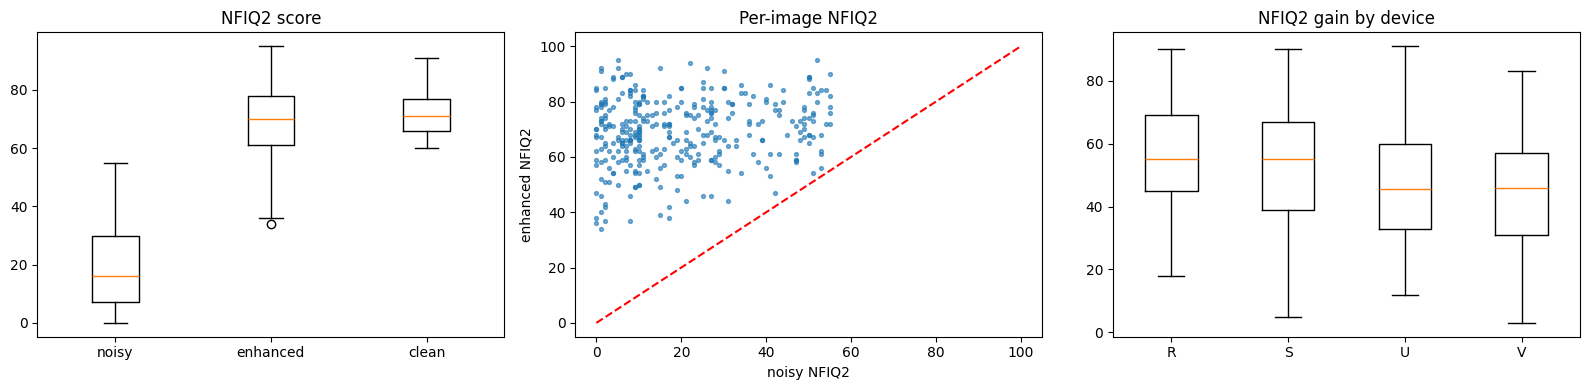

         noisy  enhanced  clean (ref)
PSNR   14.2667   19.2483          inf
SSIM    0.7289    0.8912     1.000000
RMSE   52.2094   29.3093     0.000000
NFIQ2  20.0828   69.1154    71.766272


In [31]:
r2 = res.dropna(subset=["nfiq2_noisy", "nfiq2_enhanced"])
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].boxplot([r2.nfiq2_noisy, r2.nfiq2_enhanced, r2.nfiq2_clean.dropna()], labels=["noisy", "enhanced", "clean"]); ax[0].set_title("NFIQ2 score")
ax[1].scatter(r2.nfiq2_noisy, r2.nfiq2_enhanced, s=8, alpha=.6); ax[1].plot([0, 100], [0, 100], "r--")
ax[1].set_xlabel("noisy NFIQ2"); ax[1].set_ylabel("enhanced NFIQ2"); ax[1].set_title("Per-image NFIQ2")
ax[2].boxplot([r2.nfiq2_enhanced[r2.device == d] - r2.nfiq2_noisy[r2.device == d] for d in devs], labels=devs); ax[2].set_title("NFIQ2 gain by device")
plt.tight_layout(); plt.savefig(OUT / "nfiq2_graphs.png", dpi=120); plt.show()

cols = ["psnr", "ssim", "rmse"]
final = pd.DataFrame({
    "noisy": [res[f"noisy_{m}"].mean() for m in cols] + [res.nfiq2_noisy.mean()],
    "enhanced": [res[f"enh_{m}"].mean() for m in cols] + [res.nfiq2_enhanced.mean()],
}, index=["PSNR", "SSIM", "RMSE", "NFIQ2"]).round(4)
final["clean (ref)"] = [np.inf, 1.0, 0.0, res.nfiq2_clean.mean()]
print(final); final.to_csv(OUT / "final_summary.csv")

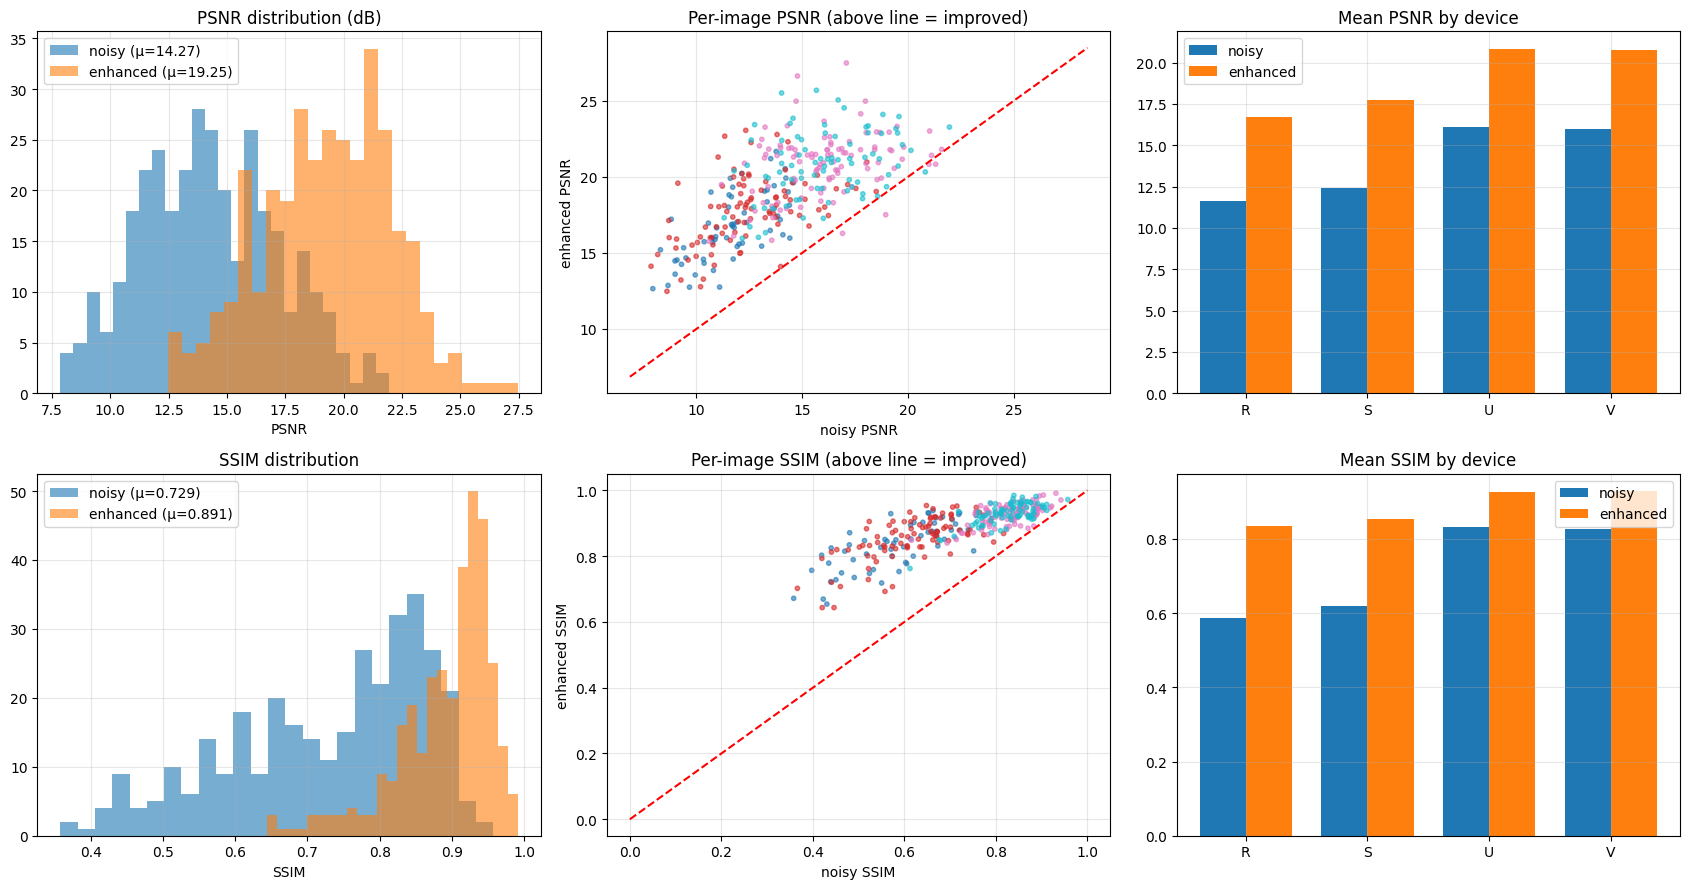

In [32]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9))

# --- PSNR ---
ax[0, 0].hist(res.noisy_psnr, bins=25, alpha=.6, label=f"noisy (μ={res.noisy_psnr.mean():.2f})")
ax[0, 0].hist(res.enh_psnr, bins=25, alpha=.6, label=f"enhanced (μ={res.enh_psnr.mean():.2f})")
ax[0, 0].set_title("PSNR distribution (dB)"); ax[0, 0].set_xlabel("PSNR"); ax[0, 0].legend()

ax[0, 1].scatter(res.noisy_psnr, res.enh_psnr, s=10, alpha=.6, c=res.device.astype("category").cat.codes, cmap="tab10")
lim = [res.noisy_psnr.min() - 1, res.enh_psnr.max() + 1]; ax[0, 1].plot(lim, lim, "r--")
ax[0, 1].set_xlabel("noisy PSNR"); ax[0, 1].set_ylabel("enhanced PSNR"); ax[0, 1].set_title("Per-image PSNR (above line = improved)")

x = np.arange(len(devs)); w = 0.38
ax[0, 2].bar(x - w/2, [res.noisy_psnr[res.device == d].mean() for d in devs], w, label="noisy")
ax[0, 2].bar(x + w/2, [res.enh_psnr[res.device == d].mean() for d in devs], w, label="enhanced")
ax[0, 2].set_xticks(x); ax[0, 2].set_xticklabels(devs); ax[0, 2].set_title("Mean PSNR by device"); ax[0, 2].legend()

# --- SSIM ---
ax[1, 0].hist(res.noisy_ssim, bins=25, alpha=.6, label=f"noisy (μ={res.noisy_ssim.mean():.3f})")
ax[1, 0].hist(res.enh_ssim, bins=25, alpha=.6, label=f"enhanced (μ={res.enh_ssim.mean():.3f})")
ax[1, 0].set_title("SSIM distribution"); ax[1, 0].set_xlabel("SSIM"); ax[1, 0].legend()

ax[1, 1].scatter(res.noisy_ssim, res.enh_ssim, s=10, alpha=.6, c=res.device.astype("category").cat.codes, cmap="tab10")
ax[1, 1].plot([0, 1], [0, 1], "r--")
ax[1, 1].set_xlabel("noisy SSIM"); ax[1, 1].set_ylabel("enhanced SSIM"); ax[1, 1].set_title("Per-image SSIM (above line = improved)")

ax[1, 2].bar(x - w/2, [res.noisy_ssim[res.device == d].mean() for d in devs], w, label="noisy")
ax[1, 2].bar(x + w/2, [res.enh_ssim[res.device == d].mean() for d in devs], w, label="enhanced")
ax[1, 2].set_xticks(x); ax[1, 2].set_xticklabels(devs); ax[1, 2].set_title("Mean SSIM by device"); ax[1, 2].legend()

for a in ax.flat: a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT / "psnr_ssim_graphs.png", dpi=130); plt.show()

In [34]:
import shutil, os
zip_base = "/kaggle/working/fingergan_out_backup"
shutil.make_archive(zip_base, "zip", "/kaggle/working", "fingergan_out")
print("Created:", zip_base + ".zip")
print(f"Size: {os.path.getsize(zip_base + '.zip') / 1e6:.1f} MB")

Created: /kaggle/working/fingergan_out_backup.zip
Size: 228.5 MB
